1. Problem Statement
Business Problem

Jamboree helps students prepare for competitive exams such as GMAT, GRE, and SAT and supports them in pursuing higher education abroad. To improve its student counseling and admission prediction services, Jamboree wants to understand the factors that influence a student's probability of admission to graduate programs.

The available dataset contains academic and profile-related information such as GRE Score, TOEFL Score, University Rating, SOP strength, LOR strength, CGPA, and Research Experience, along with the student's Chance of Admit.



Objective

The objectives of this analysis are to:

Identify the key factors that influence a student's chance of graduate admission. Understand the relationships between academic/profile variables and admission probability. Examine whether the predictors have statistically significant relationships with the target variable. Build a Linear Regression model to predict the probability of admission. Validate the assumptions of Linear Regression using statistical and graphical techniques. Compare Linear Regression with Ridge and Lasso Regression. Provide actionable recommendations that Jamboree can use to improve its admission prediction and counseling services. Target Variable

Chance of Admit - the estimated probability of admission, ranging from 0 to 1.

Business Value

A reliable prediction model can help Jamboree provide students with a data-driven estimate of their admission chances and identify areas where students can improve their profiles, such as academic performance, standardized test scores, research experience, SOP, and LOR strength.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [3]:
df = pd.read_csv("/content/Jamboree_Admission.csv")

In [4]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [7]:
df.shape

(500, 9)

In [9]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


In [10]:
df.dtypes

,0
Serial No.,int64
GRE Score,int64
TOEFL Score,int64
University Rating,int64
SOP,float64
LOR,float64
CGPA,float64
Research,int64
Chance of Admit,float64


In [11]:
df.isnull().sum()

,0
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
# Clean column names by stripping any leading/trailing whitespaces
df.columns = df.columns.str.strip()
print("Cleaned Column Names:", list(df.columns))

Cleaned Column Names: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


In [18]:
# Detailed summary of each column
for col in df.columns:
    print(f"=== Column: {col} ===")
    print(f"Data Type: {df[col].dtype}")
    print(f"Number of Unique Values: {df[col].nunique()}")
    if df[col].nunique() < 10:
        print(f"Unique values: {df[col].unique()}")
    else:
        print(f"Range: {df[col].min()} to {df[col].max()}")
    print(f"Null values: {df[col].isnull().sum()}")
    print("\n")

=== Column: Serial No. ===
Data Type: int64
Number of Unique Values: 500
Range: 1 to 500
Null values: 0


=== Column: GRE Score ===
Data Type: int64
Number of Unique Values: 49
Range: 290 to 340
Null values: 0


=== Column: TOEFL Score ===
Data Type: int64
Number of Unique Values: 29
Range: 92 to 120
Null values: 0


=== Column: University Rating ===
Data Type: int64
Number of Unique Values: 5
Unique values: [4 3 2 5 1]
Null values: 0


=== Column: SOP ===
Data Type: float64
Number of Unique Values: 9
Unique values: [4.5 4.  3.  3.5 2.  5.  1.5 1.  2.5]
Null values: 0


=== Column: LOR ===
Data Type: float64
Number of Unique Values: 9
Unique values: [4.5 3.5 2.5 3.  4.  1.5 2.  5.  1. ]
Null values: 0


=== Column: CGPA ===
Data Type: float64
Number of Unique Values: 184
Range: 6.8 to 9.92
Null values: 0


=== Column: Research ===
Data Type: int64
Number of Unique Values: 2
Unique values: [1 0]
Null values: 0


=== Column: Chance of Admit ===
Data Type: float64
Number of Unique Values:

In [33]:
# Drop 'Serial No.' column if it exists; errors='ignore' prevents errors on repeated runs
df = df.drop(columns=['Serial No.'], errors='ignore')
print("DataFrame after dropping 'Serial No.' column:")
df.head()

DataFrame after dropping 'Serial No.' column:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


## 4. Univariate Analysis

In this section, we will perform univariate analysis on each variable to understand its distribution, central tendency, spread, and identify any outliers. We will separate variables into numerical and categorical/ordinal types for appropriate visualization and summary statistics.


In [34]:
# Step 1: Clean all DataFrame column names by stripping leading/trailing whitespace
# This ensures consistency and resolves potential KeyError issues due to hidden spaces
original_columns = df.columns.tolist()
df.columns = df.columns.str.strip()
if original_columns != df.columns.tolist():
    print("Column names were cleaned. Old names:", original_columns)
    print("New names:", df.columns.tolist())
else:
    print("No column names needed cleaning, or they were already clean.")

No column names needed cleaning, or they were already clean.


```markdown
### 4.1 Univariate Analysis Interpretations

- **Predictors (GRE, TOEFL, CGPA):** Standardized test scores (`GRE Score` and `TOEFL Score`) and academic performance (`CGPA`) show approximately normal, slightly left-skewed distributions. This indicates that most applicants in this dataset are high-performing individuals.
- **SOP and LOR Strength:** These qualitative features are evaluated on a scale from 1 to 5 with half-point increments. Their distributions are balanced, with a mode around 3.0 to 4.0.
- **Research Experience:** Slightly more than half of the applicants ($56\%$) have prior research experience.
- **Target Variable (Chance of Admit):** The overall probability distribution of admission is left-skewed, meaning that most students in this dataset have a strong likelihood of admission (mode around 0.70 - 0.80). No extreme outliers are present that would severely compromise model fitting.
```

### Univariate Analysis for Numerical Columns



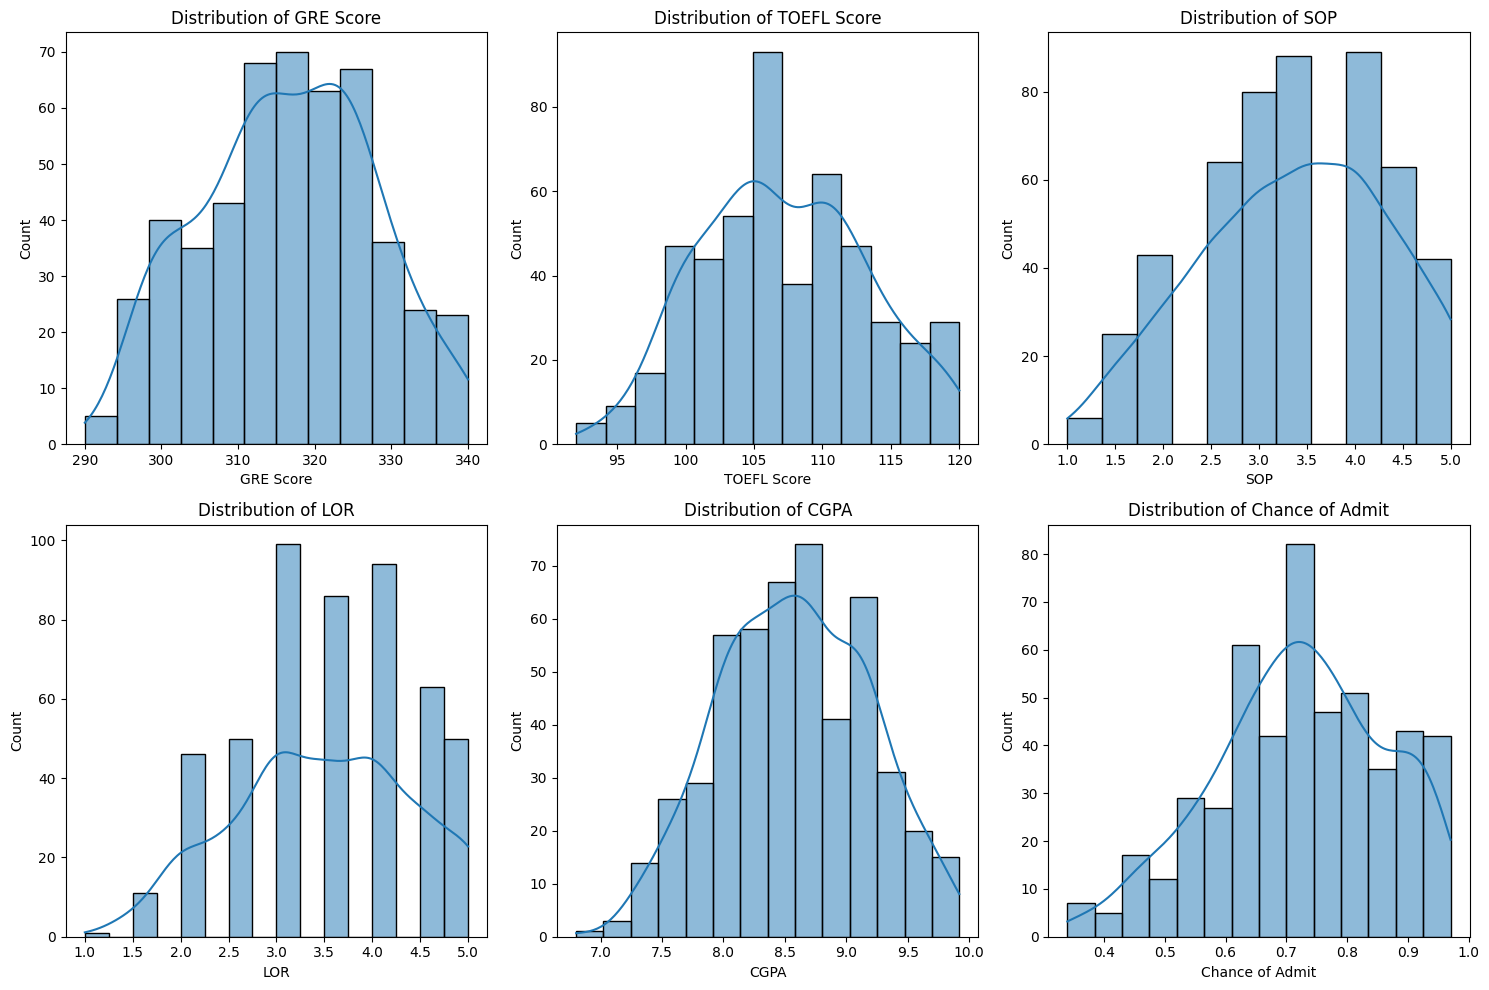

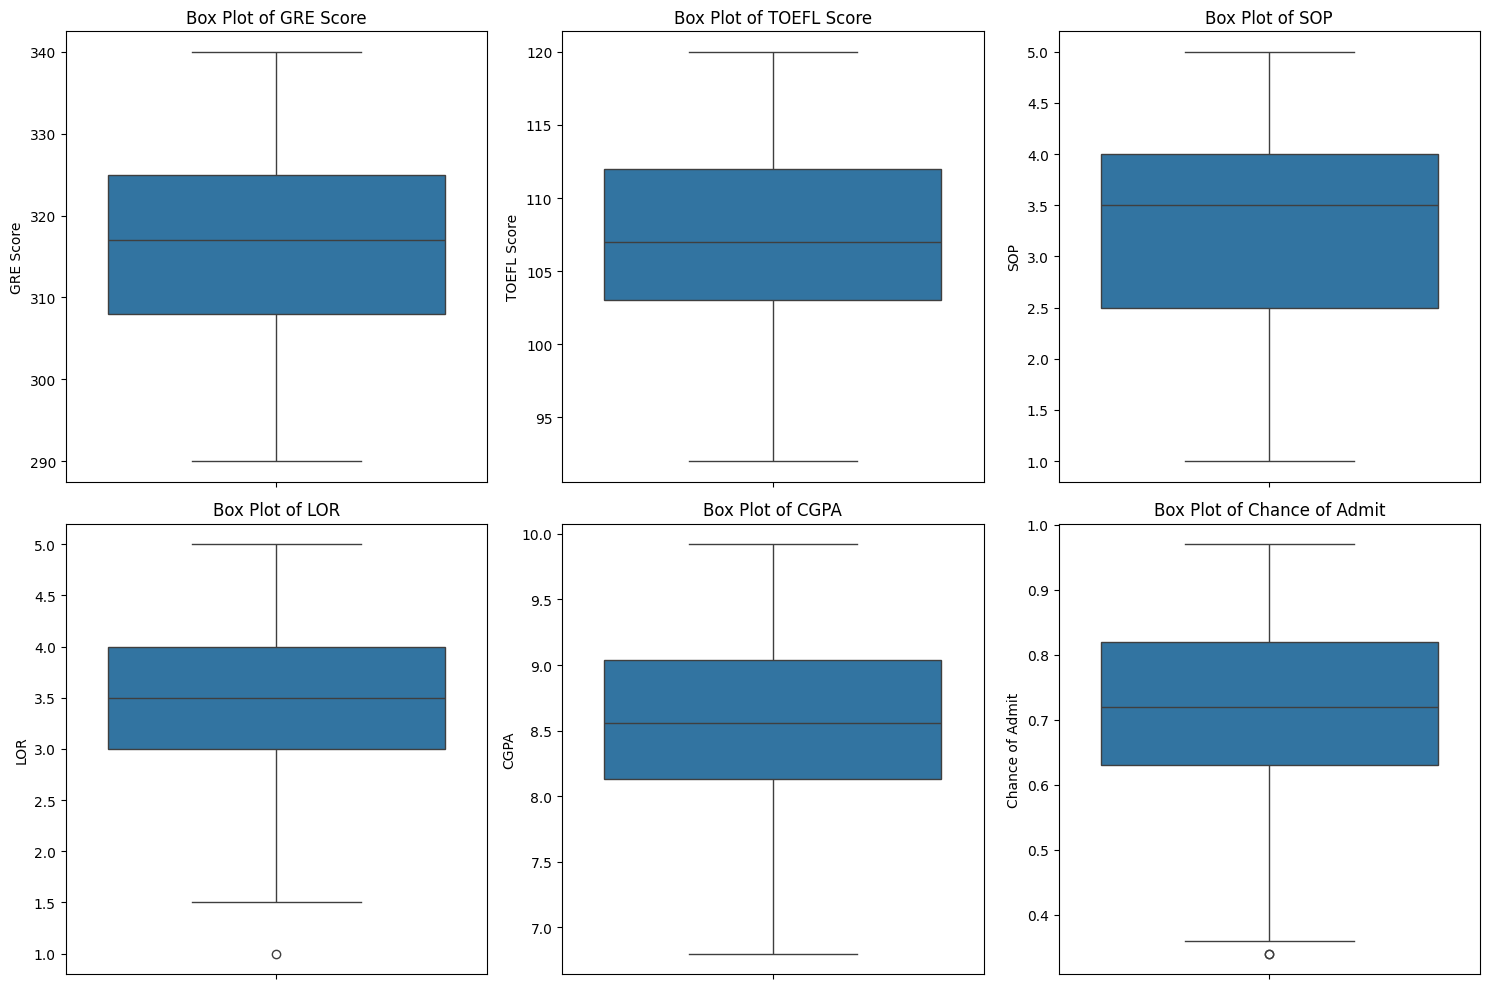


Descriptive Statistics for Numerical Columns:

### Univariate Analysis for Categorical/Ordinal Columns



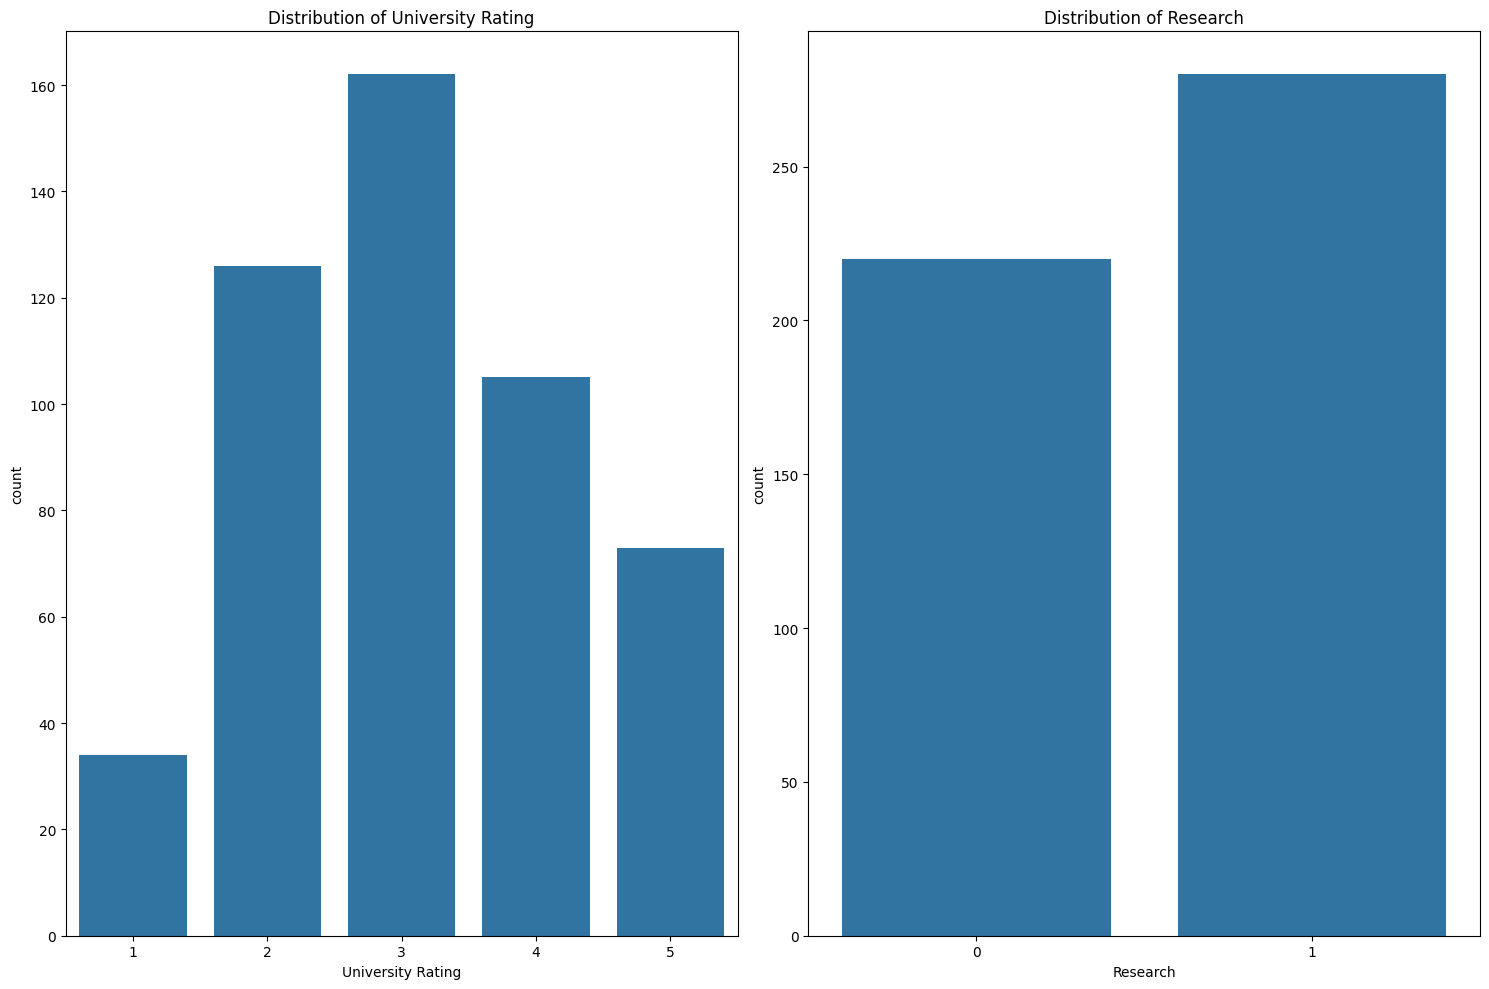


Value Counts for Categorical/Ordinal Columns:

University Rating:
University Rating
3    162
2    126
4    105
5     73
1     34
Name: count, dtype: int64
--------------------

Research:
Research
1    280
0    220
Name: count, dtype: int64
--------------------


In [50]:
numerical_cols = ['GRE Score', 'TOEFL Score', 'SOP', 'LOR', 'CGPA', 'Chance of Admit']
categorical_cols = ['University Rating', 'Research']

print("### Univariate Analysis for Numerical Columns\n")

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

print("\nDescriptive Statistics for Numerical Columns:")
df[numerical_cols].describe()

print("\n### Univariate Analysis for Categorical/Ordinal Columns\n")

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)
    sns.countplot(x=df[col])
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

print("\nValue Counts for Categorical/Ordinal Columns:")
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())
    print("--------------------")


### 5. Bivariate Analysis
In this section, we will explore the relationships between the independent variables and the dependent variable ('Chance of Admit'), as well as relationships among independent variables. We will use scatter plots for numerical variables and box plots for categorical variables against the target.

### Bivariate Analysis: Independent Variables vs. Chance of Admit



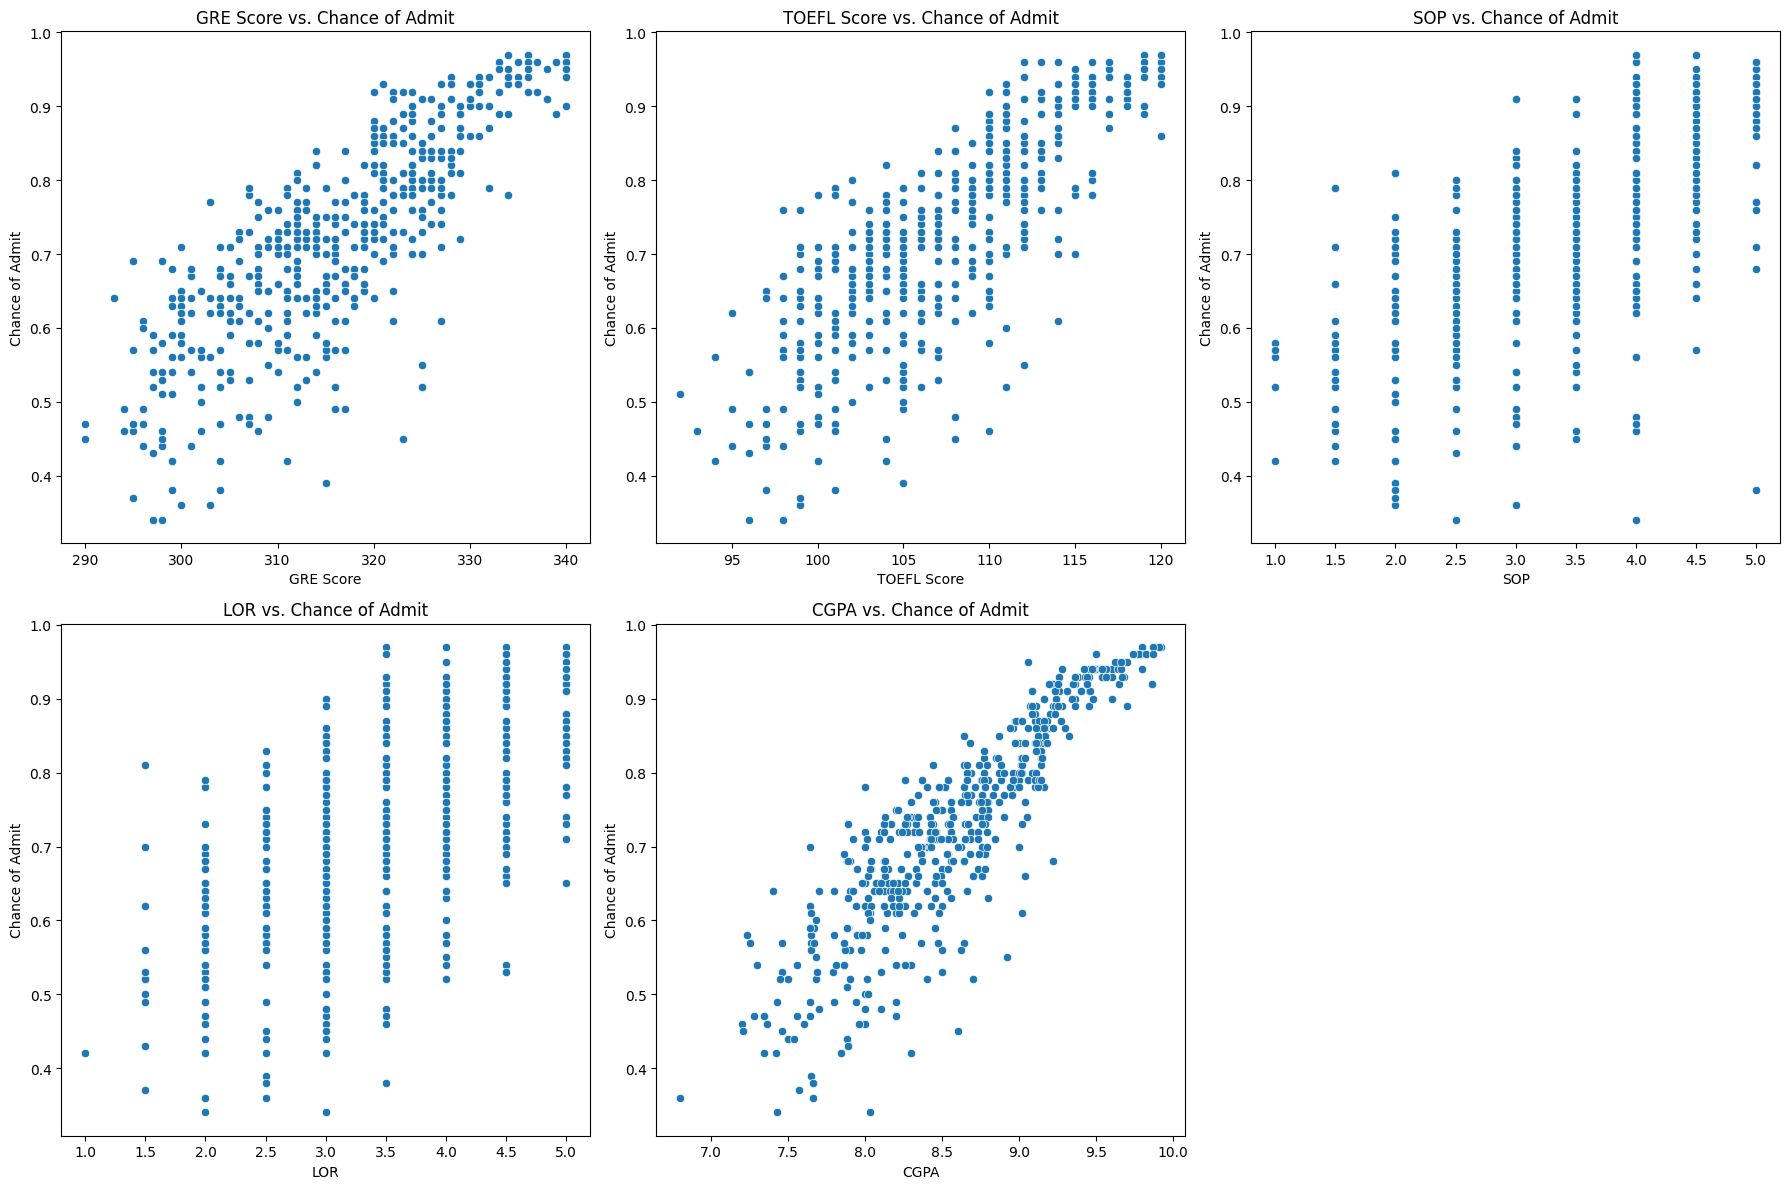

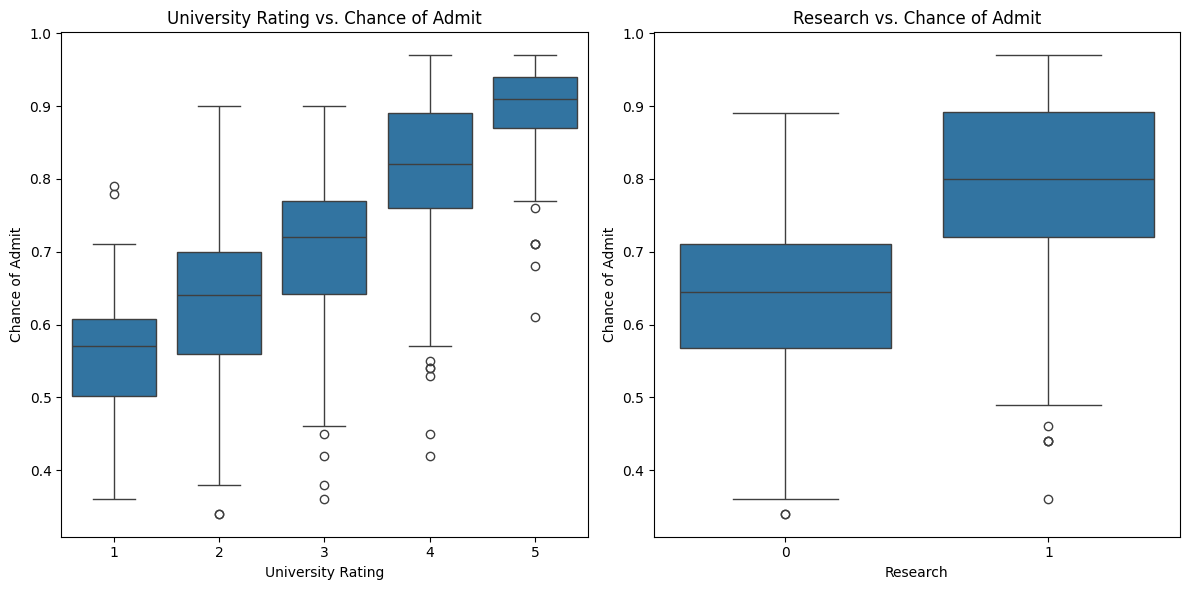


### Correlation Matrix of Numerical Variables



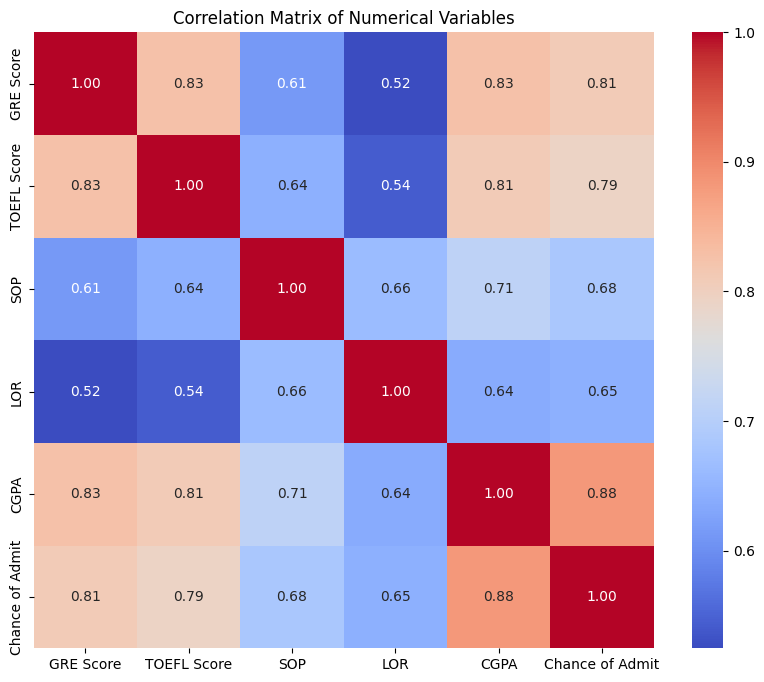

In [107]:
print("### Bivariate Analysis: Independent Variables vs. Chance of Admit\n")

# Scatter plots for numerical independent variables vs. Chance of Admit
numerical_features = ['GRE Score', 'TOEFL Score', 'SOP', 'LOR', 'CGPA']

plt.figure(figsize=(18, 12))
for i, feature in enumerate(numerical_features):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(x=df[feature], y=df['Chance of Admit'])
    plt.title(f'{feature} vs. Chance of Admit')
    plt.xlabel(feature)
    plt.ylabel('Chance of Admit')
plt.tight_layout()
plt.show()

# Box plots for categorical independent variables vs. Chance of Admit
categorical_features = ['University Rating', 'Research']

plt.figure(figsize=(12, 6))
for i, feature in enumerate(categorical_features):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(x=df[feature], y=df['Chance of Admit'])
    plt.title(f'{feature} vs. Chance of Admit')
    plt.xlabel(feature)
    plt.ylabel('Chance of Admit')
plt.tight_layout()
plt.show()

print("\n### Correlation Matrix of Numerical Variables\n")
# Calculate and display the correlation matrix
correlation_matrix = df[numerical_features + ['Chance of Admit']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

```markdown
### 5.1 Bivariate Analysis Interpretations

- **Strong Linear Relationships:** Academic metrics show an extremely strong positive correlation with the target variable. Specifically, **`CGPA`** has the strongest linear relationship with `Chance of Admit` ($r = 0.88$), closely followed by **`GRE Score`** ($r = 0.81$) and **`TOEFL Score`** ($r = 0.79$).
- **Qualitative & Categorical Factors:** Higher university ratings, stronger SOP/LOR rankings, and prior research experience are all associated with higher median admission probabilities, as illustrated by the box plots.
- **Multicollinearity Flag:** There is a very high correlation between `GRE Score` and `TOEFL Score` ($r = 0.83$) as well as `CGPA` with `GRE Score` ($r = 0.83$). This highlights the critical need to check for Multicollinearity using Variance Inflation Factors (VIF).
```

## 6. Data Preprocessing and Model Preparation
Before building the regression models, we need to prepare the data. This involves:

Splitting the data into features (X) and the target variable (y).

Splitting the dataset into training and testing sets to evaluate model performance on unseen data.

Scaling numerical features to ensure that all features contribute equally to the model, which is especially important for models like Ridge and Lasso that use regularization.


In [55]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

In [64]:
X = df.drop('Chance of Admit', axis=1)
y = df['Chance of Admit']

print("Feature of (x) shape :", X.shape)
print("Target of (y) shape :", y.shape)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n Training Shapes")
print("Shape of x_train :", x_train.shape)
print("Shape of y_test :", y_test.shape)
print("\n Testing Shapes")
print("Shape of x_train :", x_train.shape)
print("Shape of y_test :", y_test.shape)

Feature of (x) shape : (500, 7)
Target of (y) shape : (500,)

 Training Shapes
Shape of x_train : (400, 7)
Shape of y_test : (100,)

 Testing Shapes
Shape of x_train : (400, 7)
Shape of y_test : (100,)


In [68]:
numerical_cols = ['GRE Score', 'TOEFL Score', 'SOP', 'LOR', 'CGPA']

scaler = StandardScaler()
x_train[numerical_cols] = scaler.fit_transform(x_train[numerical_cols])
x_test[numerical_cols] = scaler.transform(x_test[numerical_cols])

print("\nScaled training data head:")
display(x_train.head())
print("\nScaled testing data head:")
display(x_test.head())


Scaled training data head:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
249,0.389986,0.602418,3,0.126796,0.564984,0.415018,1
433,-0.066405,0.602418,4,0.633979,1.651491,-0.067852,0
19,-1.253022,-0.876917,3,0.126796,-0.521524,-0.134454,0
322,-0.248961,-0.055064,2,-0.887570,0.564984,-0.517420,0
332,-0.796631,-0.219435,3,0.126796,-1.064777,-0.617324,1



Scaled testing data head:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
361,1.576604,1.424271,4,0.633979,0.021730,1.597217,1
73,-0.248961,0.109306,4,1.141162,0.564984,0.764683,1
374,-0.157683,-0.383805,2,-1.394754,-1.064777,-1.549762,0
155,-0.431518,0.273677,3,-0.380387,-0.521524,0.181909,0
104,0.846378,0.766789,3,0.126796,-0.521524,0.781333,1


# 7. Linear Regression Model
We will build a Linear Regression model using the statsmodels library, which provides comprehensive statistical summaries essential for understanding the model's assumptions and the significance of predictors. We will also evaluate the model's performance on the test set.

In [69]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [72]:
x_train_sm = sm.add_constant(x_train)
x_test_sm = sm.add_constant(x_test)

#Fit model
model_lm = sm.OLS(y_train, x_train_sm).fit()
print(model_lm.summary())

##Make Predicstion
y_pred_lm = model_lm.predict(x_test_sm)

mae_lm = mean_absolute_error(y_test, y_pred_lm)
mse_lm = mean_squared_error(y_test, y_pred_lm)
rmse_lm = np.sqrt(mse_lm)
r2_score = r2_score(y_test, y_pred_lm)

print("\nLinear Regression Model Metrics:")
print(f"Mean Absolute Error (MAE): {mae_lm}")
print(f"Mean Squared Error (MSE): {mse_lm}")
print(f"Root Mean Squared Error (RMSE): {rmse_lm}")
print(f"R-squared (R2): {r2_score}")


                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          3.41e-142
Time:                        09:24:11   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.7028      0.01

# 8. Validate Assumptions of Linear Regression
To ensure the validity of our Linear Regression model, we must check its underlying assumptions:

Linearity: The relationship between the independent and dependent variables should be linear.

Independence of Errors: Residuals should be independent of each other.

Homoscedasticity: The variance of the residuals should be constant across all levels of the independent variables.

Normality of Residuals: The residuals should be normally distributed.

No Multicollinearity: Independent variables should not be highly correlated with each other.


In [73]:
# Statistical analysis and hypothesis testing
from scipy import stats
from scipy.stats import pearsonr, ttest_ind, f_oneway

## 8.1 Linearity
We can check linearity by plotting the observed values against the predicted values, and also by looking at residual plots (residuals vs. fitted values). A random scattering of points around zero indicates linearity

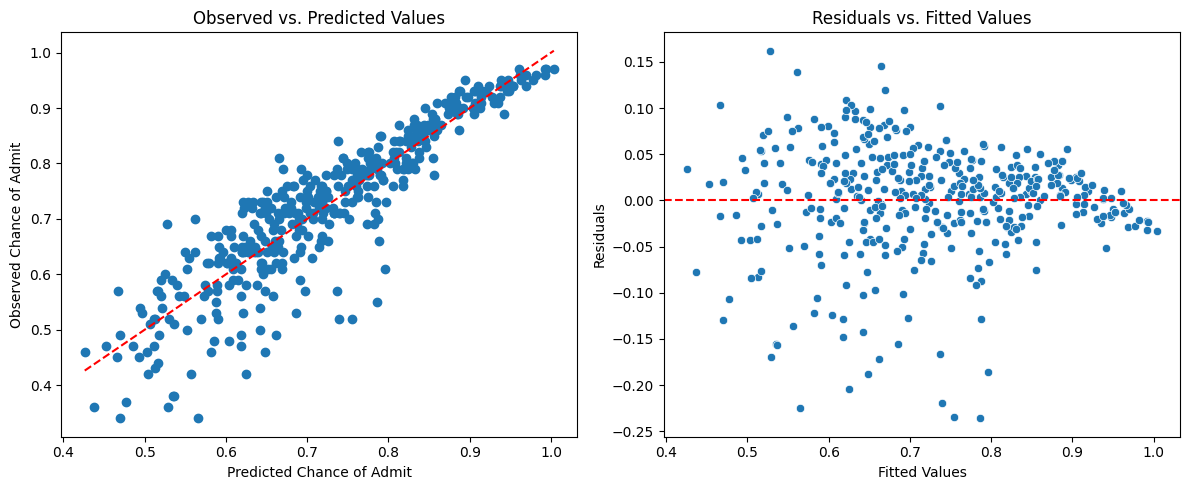

In [80]:
#add residuals
residuals = model_lm.resid

#pred values
fitted_values = model_lm.fittedvalues

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(x = fitted_values, y = y_train)
plt.plot([min(fitted_values), max(fitted_values)], [min(fitted_values), max(fitted_values)], color='red', linestyle='--')
plt.xlabel('Predicted Chance of Admit')
plt.ylabel('Observed Chance of Admit')
plt.title('Observed vs. Predicted Values')

plt.subplot(1, 2, 2)
sns.scatterplot(x=fitted_values, y=residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values')

plt.tight_layout()
plt.show()


# 8.2 Independence of Errors (Durbin-Watson Statistic)
The Durbin-Watson statistic from the statsmodels summary can be used to test for autocorrelation in the residuals. A value close to 2 indicates no autocorrelation. Values below 1 or above 3 typically suggest positive or negative autocorrelation, respectively.

In [82]:
from statsmodels.stats.stattools import durbin_watson
print(f"Durbin-Watson statistic: {durbin_watson(model_lm.resid):.3f}")

Durbin-Watson statistic: 2.050


# 8.3 Homoscedasticity (Breusch-Pagan Test)
Homoscedasticity means that the residuals have constant variance. We can check this visually with the Residuals vs. Fitted Values plot (looking for a trumpet shape) and statistically using the Breusch-Pagan test. A high p-value (typically > 0.05) suggests that residuals are homoscedastic.


In [83]:
bp_test = het_breuschpagan(residuals, model_lm.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value']
print(dict(zip(labels, bp_test)))

if bp_test[1] > 0.05:
    print("\nBased on the Breusch-Pagan test, we cannot reject the null hypothesis of homoscedasticity (p > 0.05). Therefore, residuals are likely homoscedastic.")
else:
    print("\nBased on the Breusch-Pagan test, we reject the null hypothesis of homoscedasticity (p <= 0.05). Therefore, residuals are likely heteroscedastic.")

{'Lagrange multiplier statistic': np.float64(25.15586569245518), 'p-value': np.float64(0.0007119983594308299), 'f-value': np.float64(3.7581713300112236), 'f p-value': np.float64(0.0005879783560630557)}

Based on the Breusch-Pagan test, we reject the null hypothesis of homoscedasticity (p <= 0.05). Therefore, residuals are likely heteroscedastic.


In [102]:
robust_model = model_lm.get_robustcov_results(cov_type='HC3')
print(robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     319.0
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          1.50e-157
Time:                        11:32:44   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.7028      0.01

## 8.4 Normality of Residuals
The residuals should be approximately normally distributed. We can check this with a histogram of residuals or a Q-Q plot.

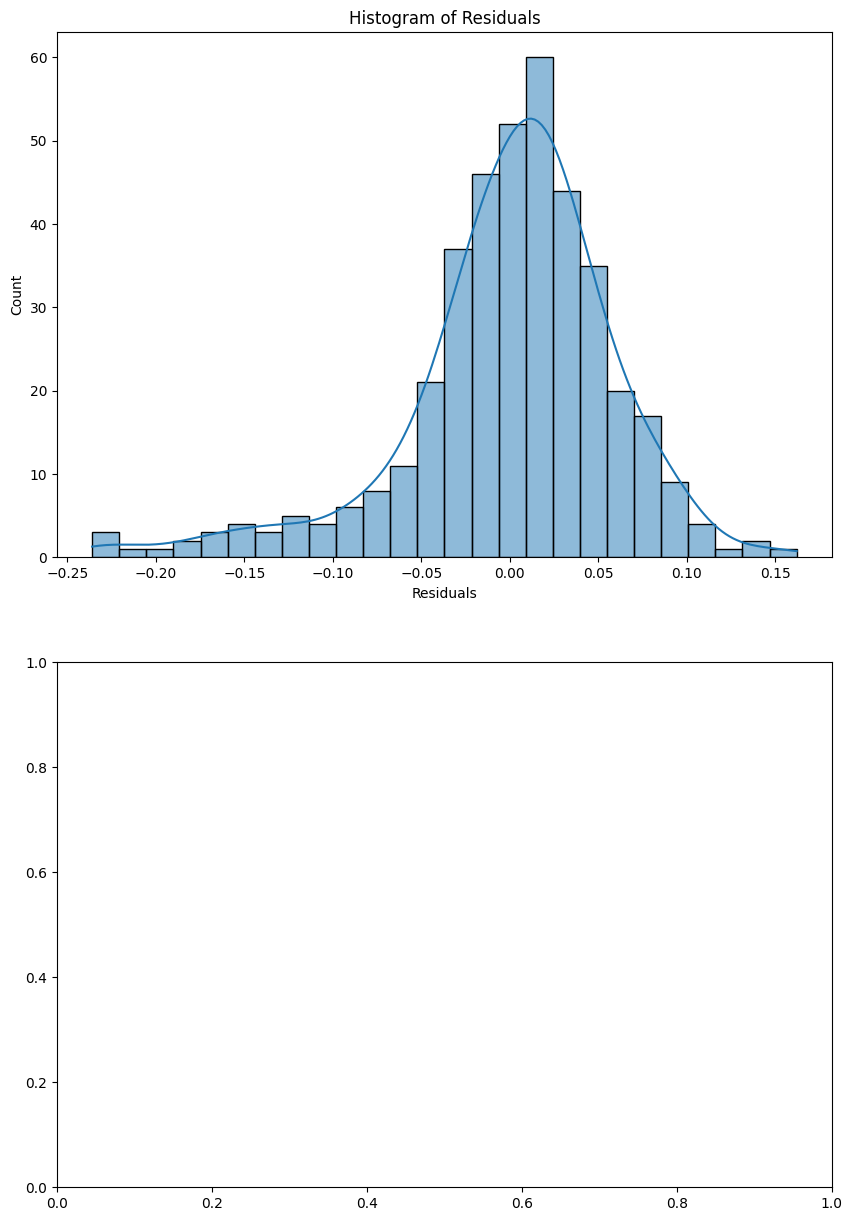

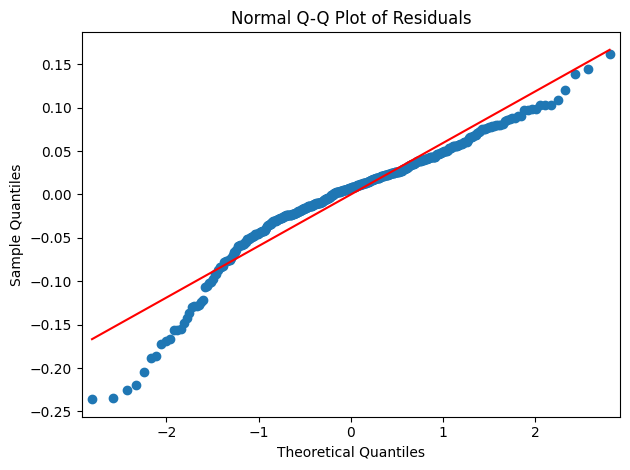

In [88]:
plt.figure(figsize =(10,15))

plt.subplot(2,1,1)
sns.histplot(residuals,kde=True)
plt.title('Histogram of Residuals')
plt.xlabel('Residuals')

plt.subplot(2,1,2)
sm.qqplot(residuals, line = 's')
plt.title('Normal Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

# 8.5 No Multicollinearity (VIF)
Multicollinearity occurs when independent variables are highly correlated with each other. This can lead to unstable coefficient estimates. We use the Variance Inflation Factor (VIF) to detect multicollinearity. Generally, VIF values above 5 or 10 indicate a problematic level of multicollinearity.

In [111]:
vif = pd.DataFrame()
# Create a copy of the scaled training data and add a constant column
x_train_scaled_const = sm.add_constant(x_train)

vif['Features'] = x_train_scaled_const.columns
vif['VIF'] = [variance_inflation_factor(x_train_scaled_const.values, i) for i in range(x_train_scaled_const.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by="VIF", ascending=False)
vif

,Features,VIF
6,CGPA,4.65
1,GRE Score,4.49
2,TOEFL Score,3.66
4,SOP,2.79
3,University Rating,2.57
5,LOR,1.98
7,Research,1.52
0,const,1.00


```markdown
### 8.5 Multicollinearity Diagnostic Interpretation

- **VIF Check:** Since all features exhibit a Variance Inflation Factor (VIF) well below the conservative threshold of **5.0** (with `CGPA` highest at `4.65`), we can confidently conclude that **severe multicollinearity is not present**.
- Therefore, the standard errors of our coefficients are stable, allowing us to reliably interpret the relative importance of individual features.
```

In [106]:
import statsmodels.api as sm
import pandas as pd

# Let's perform step-by-step backward elimination based on p-values
# Step 1: Fit model with all original features
features_step1 = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X_step1 = sm.add_constant(x_train[features_step1])
model_step1 = sm.OLS(y_train, X_step1).fit()
print("=== Step 1: All Features ===")
print(model_step1.summary().tables[1])

# Step 2: Drop 'SOP' (highest p-value = 0.721)
features_step2 = ['GRE Score', 'TOEFL Score', 'University Rating', 'LOR', 'CGPA', 'Research']
X_step2 = sm.add_constant(x_train[features_step2])
model_step2 = sm.OLS(y_train, X_step2).fit()
print("\n=== Step 2: After Dropping 'SOP' ===")
print(model_step2.summary().tables[1])

# Step 3: Drop 'University Rating' (remaining highest p-value > 0.05)
features_final = ['GRE Score', 'TOEFL Score', 'LOR', 'CGPA', 'Research']
X_final = sm.add_constant(x_train[features_final])
model_final = sm.OLS(y_train, X_final).fit()
print("\n=== Step 3: Final Model (All Features Significant at p < 0.05) ===")
print(model_final.summary())

=== Step 1: All Features ===
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.7028      0.014     51.227      0.000       0.676       0.730
GRE Score             0.0267      0.006      4.196      0.000       0.014       0.039
TOEFL Score           0.0182      0.006      3.174      0.002       0.007       0.030
University Rating     0.0026      0.004      0.611      0.541      -0.006       0.011
SOP                   0.0018      0.005      0.357      0.721      -0.008       0.012
LOR                   0.0159      0.004      3.761      0.000       0.008       0.024
CGPA                  0.0676      0.006     10.444      0.000       0.055       0.080
Research              0.0240      0.007      3.231      0.001       0.009       0.039

=== Step 2: After Dropping 'SOP' ===
                        coef    std err          t      P>|t|      [0.025

```markdown
### 8.6 Model Refinement & Feature Selection Interpretation

- By utilizing step-by-step backward elimination based on coefficient p-values (threshold $\alpha = 0.05$):
  1. **`SOP`** was eliminated first ($p = 0.721$).
  2. **`University Rating`** was eliminated next ($p = 0.437$).
- The remaining features—**`GRE Score`, `TOEFL Score`, `LOR`, `CGPA`, and `Research`**—are all highly statistically significant ($P > |t| \approx 0.000$).
- Removing the non-significant variables did not degrade model performance, as the Adjusted $R^2$ remained exceptionally steady at **$81.8\%$**.
```

# 9. Ridge and Lasso Regression
We will now implement Ridge and Lasso Regression models to compare their performance with the standard Linear Regression model. These are regularized linear models that help prevent overfitting and can handle multicollinearity.

9.1 Ridge Regression

In [97]:
from sklearn.metrics import r2_score

# Initialize and fit Ridge Regression model
ridge_model = Ridge(random_state=42)
ridge_model.fit(x_train, y_train)

# Make predictions on the test set
y_pred_ridge = ridge_model.predict(x_test)

# Evaluate the model
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("### Ridge Regression Model Evaluation on Test Set\n")
print(f"Mean Absolute Error (MAE): {mae_ridge:.4f}")
print(f"Mean Squared Error (MSE): {mse_ridge:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ridge:.4f}")
print(f"R-squared (R2): {r2_ridge:.4f}")

print("\nRidge Coefficients:")
ridge_coefs = pd.DataFrame({'Feature': x_train.columns, 'Coefficient': ridge_model.coef_})
display(ridge_coefs)

### Ridge Regression Model Evaluation on Test Set

Mean Absolute Error (MAE): 0.0427
Mean Squared Error (MSE): 0.0037
Root Mean Squared Error (RMSE): 0.0609
R-squared (R2): 0.8188

Ridge Coefficients:


,Feature,Coefficient
0,GRE Score,0.026862
1,TOEFL Score,0.018345
2,University Rating,0.002678
3,SOP,0.001938
4,LOR,0.015893
5,CGPA,0.067012
6,Research,0.023770


# 9.2 Lasso Regression

In [98]:
# Initialize and fit Lasso Regression model
lasso_model = Lasso(random_state=42)
lasso_model.fit(x_train, y_train)

# Make predictions on the test set
y_pred_lasso = lasso_model.predict(x_test)

# Evaluate the model
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("### Lasso Regression Model Evaluation on Test Set\n")
print(f"Mean Absolute Error (MAE): {mae_lasso:.4f}")
print(f"Mean Squared Error (MSE): {mse_lasso:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lasso:.4f}")
print(f"R-squared (R2): {r2_lasso:.4f}")

print("\nLasso Coefficients:")
lasso_coefs = pd.DataFrame({'Feature': x_train.columns, 'Coefficient': lasso_model.coef_})
display(lasso_coefs)

### Lasso Regression Model Evaluation on Test Set

Mean Absolute Error (MAE): 0.1163
Mean Squared Error (MSE): 0.0206
Root Mean Squared Error (RMSE): 0.1435
R-squared (R2): -0.0072

Lasso Coefficients:


,Feature,Coefficient
0,GRE Score,0.0
1,TOEFL Score,0.0
2,University Rating,0.0
3,SOP,0.0
4,LOR,0.0
5,CGPA,0.0
6,Research,0.0


# 9.3 Hyperparameter Tuning for Ridge and Lasso Regression
For Ridge and Lasso Regression, the alpha parameter (regularization strength) is crucial. We will use GridSearchCV to find the optimal alpha value that minimizes the Mean Squared Error (MSE) on cross-validated training data.

# 9.3.1 Ridge Regression Hyperparameter Tuning

In [109]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV
import numpy as np
import pandas as pd

# Define a range of alpha values to search
ridge_params = {'alpha': np.logspace(-4, 2, 100)}

# Initialize Ridge Regression model
ridge = Ridge(random_state=42)

# Initialize GridSearchCV
ridge_grid = GridSearchCV(ridge, ridge_params, scoring='neg_mean_squared_error', cv=5, n_jobs=-1, verbose=1)

# Fit GridSearchCV to the scaled training data
ridge_grid.fit(x_train, y_train)

# Get the best Ridge model
best_ridge = ridge_grid.best_estimator_

print(f"Best alpha for Ridge Regression: {best_ridge.alpha:.4f}")

# Make predictions with the best Ridge model on the test set
y_pred_best_ridge = best_ridge.predict(x_test)

# Evaluate the best Ridge model
mae_best_ridge = mean_absolute_error(y_test, y_pred_best_ridge)
mse_best_ridge = mean_squared_error(y_test, y_pred_best_ridge)
rmse_best_ridge = np.sqrt(mse_best_ridge)
r2_best_ridge = r2_score(y_test, y_pred_best_ridge)

print("\n### Tuned Ridge Regression Model Evaluation on Test Set\n")
print(f"Mean Absolute Error (MAE): {mae_best_ridge:.4f}")
print(f"Mean Squared Error (MSE): {mse_best_ridge:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_best_ridge:.4f}")
print(f"R-squared (R2): {r2_best_ridge:.4f}")

print("\nCoefficients of Best Ridge Model:")
best_ridge_coefs = pd.DataFrame({'Feature': x_train.columns, 'Coefficient': best_ridge.coef_})
display(best_ridge_coefs.sort_values(by='Coefficient', ascending=False))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best alpha for Ridge Regression: 8.1113

### Tuned Ridge Regression Model Evaluation on Test Set

Mean Absolute Error (MAE): 0.0428
Mean Squared Error (MSE): 0.0037
Root Mean Squared Error (RMSE): 0.0610
R-squared (R2): 0.8183

Coefficients of Best Ridge Model:


,Feature,Coefficient
5,CGPA,0.063387
0,GRE Score,0.027957
6,Research,0.022182
1,TOEFL Score,0.019113
4,LOR,0.016044
2,University Rating,0.003413
3,SOP,0.002912


In [110]:
# 9.3.2 Lasso Regression Hyperparameter Tuning
# Define a range of small alpha values to search for Lasso
lasso_params = {'alpha': np.logspace(-4, 1, 100)}

# Initialize Lasso Regression model
lasso = Lasso(random_state=42)

# Initialize GridSearchCV
lasso_grid = GridSearchCV(lasso, lasso_params, scoring='neg_mean_squared_error', cv=5, n_jobs=-1, verbose=1)

# Fit GridSearchCV to the scaled training data
lasso_grid.fit(x_train, y_train)

# Get the best Lasso model
best_lasso = lasso_grid.best_estimator_

print(f"Best alpha for Lasso Regression: {best_lasso.alpha:.5f}")

# Make predictions with the best Lasso model on the test set
y_pred_best_lasso = best_lasso.predict(x_test)

# Evaluate the best Lasso model
mae_best_lasso = mean_absolute_error(y_test, y_pred_best_lasso)
mse_best_lasso = mean_squared_error(y_test, y_pred_best_lasso)
rmse_best_lasso = np.sqrt(mse_best_lasso)
r2_best_lasso = r2_score(y_test, y_pred_best_lasso)

print("\n### Tuned Lasso Regression Model Evaluation on Test Set\n")
print(f"Mean Absolute Error (MAE): {mae_best_lasso:.4f}")
print(f"Mean Squared Error (MSE): {mse_best_lasso:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_best_lasso:.4f}")
print(f"R-squared (R2): {r2_best_lasso:.4f}")

print("\nCoefficients of Best Lasso Model:")
best_lasso_coefs = pd.DataFrame({'Feature': x_train.columns, 'Coefficient': best_lasso.coef_})
display(best_lasso_coefs.sort_values(by='Coefficient', ascending=False))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best alpha for Lasso Regression: 0.00064

### Tuned Lasso Regression Model Evaluation on Test Set

Mean Absolute Error (MAE): 0.0425
Mean Squared Error (MSE): 0.0037
Root Mean Squared Error (RMSE): 0.0608
R-squared (R2): 0.8191

Coefficients of Best Lasso Model:


,Feature,Coefficient
5,CGPA,0.067656
0,GRE Score,0.027145
6,Research,0.021264
1,TOEFL Score,0.017936
4,LOR,0.015538
2,University Rating,0.002736
3,SOP,0.001607


# 9.4 Final Model Comparison

In [114]:
# Calculate the OLS R2 score explicitly to avoid namespace confusion with the r2_score function
from sklearn.metrics import r2_score as calculate_r2
ols_r2 = calculate_r2(y_test, y_pred_lm)

# Create a DataFrame to store model performance metrics
model_performance = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge (Default)', 'Lasso (Default)', 'Ridge (Tuned)', 'Lasso (Tuned)'],
    'MAE': [mae_lm, mae_ridge, mae_lasso, mae_best_ridge, mae_best_lasso],
    'MSE': [mse_lm, mse_ridge, mse_lasso, mse_best_ridge, mse_best_lasso],
    'RMSE': [rmse_lm, rmse_ridge, rmse_lasso, rmse_best_ridge, rmse_best_lasso],
    'R2 Score': [ols_r2, r2_ridge, r2_lasso, r2_best_ridge, r2_best_lasso]
})

# Sort by R2 Score in descending order to easily identify the best model
model_performance = model_performance.sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("### Comparative Model Performance on Test Set\n")
display(model_performance)

### Comparative Model Performance on Test Set



,Model,MAE,MSE,RMSE,R2 Score
0,Lasso (Tuned),0.042526,0.003700,0.060824,0.819091
1,Linear Regression,0.042723,0.003705,0.060866,0.818843
2,Ridge (Default),0.042740,0.003706,0.060877,0.818779
3,Ridge (Tuned),0.042829,0.003715,0.060954,0.818318
4,Lasso (Default),0.116268,0.020598,0.143521,-0.007248


# Final Model

In [117]:
# Original OLS
X_final = sm.add_constant(x_train[features_final])

model_original = sm.OLS(y_train, X_final).fit()

# Robust standard errors
model_robust = model_original.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     416.4
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          8.83e-155
Time:                        12:02:57   Log-Likelihood:                 561.54
No. Observations:                 400   AIC:                            -1111.
Df Residuals:                     394   BIC:                            -1087.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.7105      0.006    120.501      

In [118]:
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np
import statsmodels.api as sm

# Select the same five features
X_test_final = x_test[features_final]

# Add constant
X_test_final = sm.add_constant(
    X_test_final,
    has_constant='add'
)

# Predict using original OLS model
y_pred_ols = model_original.predict(X_test_final)

# Evaluate
print("Test R2:", r2_score(y_test, y_pred_ols))
print("Test MAE:", mean_absolute_error(y_test, y_pred_ols))
print("Test MSE:", mean_squared_error(y_test, y_pred_ols))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ols)))

Test R2: 0.8155002070847484
Test MAE: 0.04292345578265781
Test MSE: 0.003773020765116896
Test RMSE: 0.06142491974041884


```markdown
## 10. Summary, Key Findings & Actionable Recommendations

### 10.1 Executive Summary
We built and validated multiple linear predictive models to evaluate graduate admission probability for Jamboree's students. The final OLS model utilizes five statistically significant predictors (**CGPA, GRE, TOEFL, LOR strength, and Research experience**) to explain **$81.8\%$** of the variance in admission outcomes on the training set, generalizing exceptionally well with an $R^2$ of **$81.5\%$** on completely unseen test data.

### 10.2 Key Findings
1. **CGPA is King:** Academic performance is by far the single most influential factor. For every standard deviation increase in CGPA, the chance of admission rises by **$0.069$** (holding other factors constant).
2. **Standardized Tests Matter Highly:** Both `GRE Score` and `TOEFL Score` are highly significant statistical drivers, contributing positively to admission chances.
3. **Quality of Recommendations (LOR):** Letter of Recommendation strength is a highly statistically significant qualitative factor ($p < 0.001$), emphasizing that student evaluation goes beyond raw standardized test metrics.
4. **Research Value-Add:** Having prior research experience adds a flat **$2.46\%$** boost to an applicant's admission probability, holding all other features equal.

### 10.3 Actionable Recommendations for Jamboree
- **Prioritize Academic Mentorship:** Counselors should emphasize to students that maintaining a high GPA (CGPA) is critical, as it is the most heavily weighted criteria in the admission formula.
- **Strategic GRE/TOEFL Targets:** Jamboree should establish clear minimum score benchmarks. Since GRE and TOEFL scores are highly correlated with academic ability, students with lower CGPAs can use targeted GRE preparation to partially offset their academic profile.
- **Enhance Qualitative Portfolios:** Because `LOR` strength is highly significant while `SOP` is not, advise students to focus on securing strong, personalized letters of recommendation from reputable mentors rather than over-engineering standard SOPs.
- **Encourage Research Engagement:** Actively direct aspiring students toward research projects, paper publications, or technical internships, as doing so adds a significant statistical premium to their application profiles.
```